# TabICL et prédiction conforme —Analyse de Fitness Club

Prédiction conforme (split conformal, CV+, Jackknife+) avec **TabICL**, un modèle de fondation tabulaire pré-entraîné : `fit` garde les lignes d'entraînement comme contexte, `predict_proba` fait un passage dans le transformeur, sans entraînement ni hyperparamètres. Le découpage et les fonctions conformes sont ceux de `notebook_xgboost.ipynb` ; la comparaison des deux modèles est dans `comparaison.ipynb`.

## 1. Import + générer/récupérer le découpage

In [1]:
import time
import tempfile
import contextlib
import io
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import warnings
import torch
from importlib.metadata import version
from tabicl import TabICLClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

from generation_decoupage import generation_decoupage

plt.rcParams["figure.figsize"] = (7, 4)
warnings.filterwarnings("ignore")

# Matériel : GPU Apple (mps) si dispo, sinon cuda, sinon cpu
if torch.backends.mps.is_available():
    DEVICE = "mps"
elif torch.cuda.is_available():
    DEVICE = "cuda"
else:
    DEVICE = "cpu"
print("tabicl", version("tabicl"), "| torch", torch.__version__, "| device :", DEVICE)

dossier = Path.cwd()

# Graine du découpage
GRAINE = 90 #<--------------------------------

decoupage = generation_decoupage(
    fichier_csv=dossier / "fitness_club_modifie.csv",
    graine=GRAINE,
    colonne_cible="attended",
)

#variables
donnees = decoupage["donnees_decoupage"]
fichier_decoupage = decoupage["fichier_decoupage"]
X_D = decoupage["X_D"]
X_test = decoupage["X_test"]
y_D = decoupage["y_D"]
y_test = decoupage["y_test"]
X_train = decoupage["X_train"]
X_cal = decoupage["X_cal"]
y_train = decoupage["y_train"]
y_cal = decoupage["y_cal"]
classes = decoupage["classes"]

#affichage
X = donnees.drop(columns=["attended", "TRAIN_TEST", "SPLIT_CONFORMAL"])
y = donnees["attended"]

print("Dimensions du CSV découpé :", donnees.shape)
print("Variables explicatives :", X.shape[1])
print("Classes de la cible :", list(classes))


tabicl 2.2.0 | torch 2.15.0 | device : mps
Découpage créé : /Users/elias/Documents/Courses/5A/PIR/Projet_RI_TabFn/decoupage_90.csv
Graine : 90
Groupe D : 1124 lignes | Test final : 375 lignes
Entraînement : 786 lignes | Calibration : 338 lignes
Dimensions du CSV découpé : (1499, 21)
Variables explicatives : 18
Classes de la cible : ['No', 'Yes']


## 2. Vérifications datas

In [2]:
display(X.head())
print("\nTypes des colonnes :")
print(X.dtypes)
print("\nValeurs manquantes :")
print(X.isna().sum()[X.isna().sum() > 0])
print("\nRépartition de la cible :")
print(y.value_counts(normalize=True).round(3))

,months_as_member,weight,days_before,day_of_week_Fri,day_of_week_Mon,day_of_week_Sat,day_of_week_Sun,day_of_week_Thu,day_of_week_Tue,day_of_week_Wed,time_AM,time_PM,category_-,category_Aqua,category_Cycling,category_HIIT,category_Strength,category_Yoga
0,15,65.47,6,0,0,0,0,0,0,1,1,0,0,0,0,1,0,0
1,18,77.85,8,0,0,0,0,1,0,0,1,0,0,0,0,0,1,0
2,13,67.26,10,1,0,0,0,0,0,0,1,0,0,0,1,0,0,0
3,7,86.70,12,0,0,1,0,0,0,0,1,0,0,0,0,1,0,0
4,5,135.18,8,0,0,0,0,1,0,0,1,0,0,0,0,1,0,0



Types des colonnes :
months_as_member       int64
weight               float64
days_before            int64
day_of_week_Fri        int64
day_of_week_Mon        int64
day_of_week_Sat        int64
day_of_week_Sun        int64
day_of_week_Thu        int64
day_of_week_Tue        int64
day_of_week_Wed        int64
time_AM                int64
time_PM                int64
category_-             int64
category_Aqua          int64
category_Cycling       int64
category_HIIT          int64
category_Strength      int64
category_Yoga          int64
dtype: object

Valeurs manquantes :
weight    19
dtype: int64

Répartition de la cible :
attended
No     0.697
Yes    0.303
Name: proportion, dtype: float64


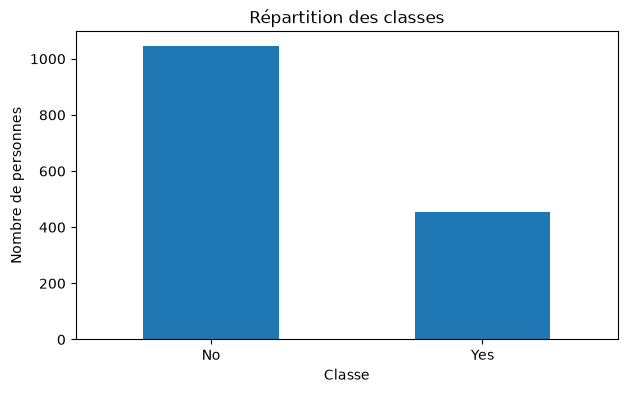

In [3]:
y.value_counts().plot(kind="bar", rot=0)
plt.title("Répartition des classes")
plt.xlabel("Classe")
plt.ylabel("Nombre de personnes")
plt.show()

## 3. Entraîner TabICL

Une seule instance, réutilisée dans tout le notebook (le checkpoint n'est chargé qu'une fois). Par défaut TabICL fait 8 passages par prédiction (`n_estimators=8` : colonnes / classes présentées dans 8 ordres différents) et moyenne. `random_state=0` partout : pour TabICL il fixe ces mélanges, donc il a un petit effet sur les probabilités.

Le tout premier appel est lent (chargement du modèle, compilation mps) : on fait un échauffement non chronométré.

In [4]:
modele_tfm = TabICLClassifier(device=DEVICE, random_state=0)

# Échauffement (chargement du checkpoint, non chronométré)
modele_tfm.fit(X_D[:50], y_D[:50]); modele_tfm.predict_proba(X_test[:5])

debut = time.time()
modele_tfm.fit(X_D, y_D)
probabilites_test = modele_tfm.predict_proba(X_test)
TEMPS_UN_FIT = time.time() - debut
print("Temps d'entraînement et de prédiction :", round(TEMPS_UN_FIT, 2), "secondes")

Temps d'entraînement et de prédiction : 1.74 secondes


In [5]:
# Chaque ligne contient la probabilité prédite pour chaque classe.
display(pd.DataFrame(
    probabilites_test[:5],
    columns=[f"P({nom})" for nom in classes]
).round(3))

def metriques_point(y_vrai, proba):
    # Accuracy + précision / rappel / F1 en moyenne macro (les deux classes comptent autant).
    pred = proba.argmax(axis=1)
    return {
        "accuracy": accuracy_score(y_vrai, pred),
        "precision_macro": precision_score(y_vrai, pred, average="macro", zero_division=0),
        "recall_macro": recall_score(y_vrai, pred, average="macro", zero_division=0),
        "f1_macro": f1_score(y_vrai, pred, average="macro", zero_division=0),
    }

print(pd.Series(metriques_point(y_test, probabilites_test)).round(3))
print("Classe majoritaire:",
      round(max(np.mean(y_test), 1 - np.mean(y_test)), 3))

,P(No),P(Yes)
0,0.395,0.605
1,0.965,0.035
2,0.883,0.117
3,0.753,0.247
4,0.981,0.019


accuracy           0.797
precision_macro    0.770
recall_macro       0.726
f1_macro           0.741
dtype: float64
Classe majoritaire: 0.696


## 4. Split conformal

On recupere le train D et ses 2 modalités :
- **entraînement** : 0;
- **calibration** : 1 (calcul seuil de confiance)

In [6]:
debut = time.time()
modele_tfm.fit(X_train, y_train)
proba_cal = modele_tfm.predict_proba(X_cal)
proba_test_split = modele_tfm.predict_proba(X_test)
TEMPS_SPLIT = time.time() - debut

print("Entraînement :", X_train.shape)
print("Calibration :", X_cal.shape)
print("Test final :", X_test.shape)
print("Temps split :", round(TEMPS_SPLIT, 2), "secondes")

Entraînement : (786, 18)
Calibration : (338, 18)
Test final : (375, 18)
Temps split : 3.74 secondes


La fonction ci-dessous calcule le seuil à partir des données de calibration, puis garde pour chaque personne les classes dont la probabilité est assez élevée.

In [7]:
def split_conformal(proba_cal, y_cal, proba_test, alpha):
    # Score de la vraie classe pour chaque personne de calibration.
    n = len(y_cal)
    scores = 1 - proba_cal[np.arange(n), y_cal]

    # Seuil de calibration (quantile corrigé pour la taille de l'échantillon).
    rang = int(np.ceil((n + 1) * (1 - alpha)))
    rang = min(rang, n)
    seuil = np.sort(scores)[rang - 1]

    # Une classe est gardée si sa probabilité est suffisante.
    ensembles = proba_test >= 1 - seuil
    return ensembles


def mesurer_ensembles(ensembles, vraies_classes):
    tailles = ensembles.sum(axis=1)
    couverture = ensembles[np.arange(len(vraies_classes)), vraies_classes].mean()

    return {
        "coverage": couverture,
        "avg_set_size": tailles.mean(),
        "singleton_rate": (tailles == 1).mean(),
        "empty_rate": (tailles == 0).mean()
    }

In [8]:
alpha = 0.1
ensembles_split = split_conformal(proba_cal, y_cal, proba_test_split, alpha)
resultat = mesurer_ensembles(ensembles_split, y_test)

print("Couverture visée :", 1 - alpha)
print(pd.Series(resultat).round(3))

Couverture visée : 0.9
coverage          0.931
avg_set_size      1.381
singleton_rate    0.619
empty_rate        0.000
dtype: float64


- `coverage` : 0.931 > 0.9, c'est bon
- `avg_set_size` : 1.381
- `singleton_rate` : 61.9 % des ensembles ne contiennent qu'une classe, le reste est indécis

### Split sur plusieurs graines

Une seule graine = un seul tirage du test (375 personnes) et de la calibration (338) : la couverture bouge d'environ ±2 points d'un tirage à l'autre. On refait donc le split conformal sur les graines 0, 1, 2, 3, 90 et on donne la moyenne ± l'écart-type. Les fichiers `decoupage_<graine>.csv` sont écrits dans un dossier temporaire pour ne pas encombrer le dépôt.

In [9]:
GRAINES = [0, 1, 2, 3, 90]
alphas = [0.05, 0.1, 0.2]
dossier_tmp = tempfile.mkdtemp()

decoupages = {}
for g in GRAINES:
    with contextlib.redirect_stdout(io.StringIO()):  # on cache les messages de generation_decoupage
        decoupages[g] = generation_decoupage(
            fichier_csv=dossier / "fitness_club_modifie.csv",
            graine=g, colonne_cible="attended", dossier_sortie=dossier_tmp,
        )

lignes_split = []
for g, d in decoupages.items():
    debut = time.time()
    m = modele_tfm
    m.fit(d["X_train"], d["y_train"])
    p_cal = m.predict_proba(d["X_cal"])
    p_test = m.predict_proba(d["X_test"])
    t = time.time() - debut
    for alpha in alphas:
        ensembles = split_conformal(p_cal, d["y_cal"], p_test, alpha)
        lignes_split.append({"graine": g, "methode": "Split", "alpha": alpha,
                             **mesurer_ensembles(ensembles, d["y_test"]),
                             **metriques_point(d["y_test"], p_test), "temps_s": t})

multi_split = pd.DataFrame(lignes_split)
display(multi_split.pivot(index="graine", columns="alpha", values="coverage").round(3))
display(multi_split.groupby("alpha")[["coverage", "avg_set_size", "singleton_rate", "accuracy", "f1_macro"]]
        .agg(["mean", "std"]).round(3))

alpha,0.05,0.10,0.20
graine,,,
0,0.976,0.947,0.832
1,0.931,0.877,0.792
2,0.939,0.888,0.792
3,0.971,0.923,0.837
90,0.965,0.931,0.835


coverage        avg_set_size        singleton_rate        accuracy  \
          mean    std         mean    std           mean    std     mean   
alpha                                                                      
0.05     0.956  0.020        1.499  0.083          0.501  0.083    0.789   
0.10     0.913  0.029        1.325  0.084          0.675  0.084    0.789   
0.20     0.818  0.023        1.061  0.035          0.939  0.035    0.789   

             f1_macro         
         std     mean    std  
alpha                         
0.05   0.014    0.726  0.025  
0.10   0.014    0.726  0.025  
0.20   0.014    0.726  0.025

## 5. Jackknife+ et CV+

Def rappel:
**Jackknife+** : on entraîne un modèle en retirant une seule ligne, et on recommence pour chaque ligne.
**CV+** : folds


In [10]:
def entrainer_et_predire(X_apprentissage, y_apprentissage, X_a_predire):
    # Pas de réentraînement des poids : fit = nouveau contexte, predict_proba = passage dans le transformeur.
    modele_tfm.fit(X_apprentissage, y_apprentissage)
    return modele_tfm.predict_proba(X_a_predire)


def calculer_scores_plus(X, y, X_test, methode="jackknife", nombre_folds=10):
    n = len(y)
    scores_vrais = np.zeros(n)
    scores_test = None

    if methode == "jackknife":
        # Chaque ligne est retirée à tour de rôle.
        groupes = [(np.delete(np.arange(n), i), np.array([i])) for i in range(n)]
    else:
        # CV+ : on retire un groupe à la fois.
        cv = StratifiedKFold(n_splits=nombre_folds, shuffle=True, random_state=0)
        groupes = list(cv.split(X, y))

    for train_ids, val_ids in groupes:
        X_a_predire = np.vstack([X[val_ids], X_test])
        probas = entrainer_et_predire(X[train_ids], y[train_ids], X_a_predire)

        # Score des lignes qui ont été laissées de côté.
        probas_val = probas[:len(val_ids)]
        scores_vrais[val_ids] = 1 - probas_val[np.arange(len(val_ids)), y[val_ids]]

        # Scores des classes proposées pour le test.
        probas_test_plus = probas[len(val_ids):]
        if scores_test is None:
            scores_test = np.zeros((n, len(X_test), probas_test_plus.shape[1]))
        scores_test[val_ids] = 1 - probas_test_plus

    return scores_vrais, scores_test


def construire_ensembles_plus(scores_vrais, scores_test, alpha):
    # On compte combien de modèles jugent chaque classe moins plausible.
    nombre_rejets = (scores_test > scores_vrais[:, None, None]).sum(axis=0)
    return nombre_rejets < (1 - alpha) * (len(scores_vrais) + 1)


def proba_moyenne_plus(scores_test):
    # Prédiction ponctuelle pour CV+/Jackknife+ : moyenne des probas des modèles leave-out.
    return (1 - scores_test).mean(axis=0)

### CV+ 

In [11]:
debut = time.time()
scores_cv, predictions_cv = calculer_scores_plus(
    X_D, y_D, X_test, methode="cv", nombre_folds=10
)
TEMPS_CV = time.time() - debut
print("Temps CV+ :", round(TEMPS_CV, 1), "secondes")

for alpha in [0.05, 0.1, 0.2]:
    ensembles = construire_ensembles_plus(scores_cv, predictions_cv, alpha)
    print("alpha =", alpha, mesurer_ensembles(ensembles, y_test))

Temps CV+ : 23.6 secondes
alpha = 0.05 {'coverage': np.float64(0.96), 'avg_set_size': np.float64(1.5066666666666666), 'singleton_rate': np.float64(0.49333333333333335), 'empty_rate': np.float64(0.0)}
alpha = 0.1 {'coverage': np.float64(0.92), 'avg_set_size': np.float64(1.3546666666666667), 'singleton_rate': np.float64(0.6453333333333333), 'empty_rate': np.float64(0.0)}
alpha = 0.2 {'coverage': np.float64(0.824), 'avg_set_size': np.float64(1.056), 'singleton_rate': np.float64(0.944), 'empty_rate': np.float64(0.0)}


alpha=0.05 : avg_set_size=1.51, singleton rate ≈ 0.49

alpha=0.2 : avg_set_size=1.06, singleton rate 0.94

### CV+ sur plusieurs graines

Mêmes graines que pour le split (les folds de CV+ restent tirés avec `random_state=0`).

In [12]:
lignes_cv = []
for g, d in decoupages.items():
    debut = time.time()
    s_cv, pr_cv = calculer_scores_plus(d["X_D"], d["y_D"], d["X_test"], methode="cv", nombre_folds=10)
    t = time.time() - debut
    m_cv = metriques_point(d["y_test"], proba_moyenne_plus(pr_cv))
    for alpha in alphas:
        ensembles = construire_ensembles_plus(s_cv, pr_cv, alpha)
        lignes_cv.append({"graine": g, "methode": "CV+", "alpha": alpha,
                          **mesurer_ensembles(ensembles, d["y_test"]), **m_cv, "temps_s": t})

multi_cv = pd.DataFrame(lignes_cv)
display(multi_cv.pivot(index="graine", columns="alpha", values="coverage").round(3))
display(multi_cv.groupby("alpha")[["coverage", "avg_set_size", "singleton_rate", "accuracy", "f1_macro"]]
        .agg(["mean", "std"]).round(3))

alpha,0.05,0.10,0.20
graine,,,
0,0.963,0.933,0.813
1,0.960,0.891,0.787
2,0.952,0.891,0.781
3,0.960,0.925,0.837
90,0.960,0.920,0.824


coverage        avg_set_size        singleton_rate        accuracy  \
          mean    std         mean    std           mean    std     mean   
alpha                                                                      
0.05     0.959  0.004        1.489  0.037          0.511  0.037    0.787   
0.10     0.912  0.020        1.323  0.052          0.677  0.052    0.787   
0.20     0.809  0.024        1.041  0.019          0.959  0.019    0.787   

             f1_macro         
         std     mean    std  
alpha                         
0.05   0.019    0.725  0.032  
0.10   0.019    0.725  0.032  
0.20   0.019    0.725  0.032

### Lancer Jackknife+ CHANGER TRUE/FALSE parce que c'est bien long sinon

On estime d'abord la durée (1124 fits × temps d'un fit+predict) ; il n'est lancé que si l'estimation est sous 45 minutes (environ 30 min sur un MacBook Air avec le GPU mps).

In [13]:
# Mettre True pour lancer Jackknife+, False pour le passer.
LANCER_JACKKNIFE = True
LIMITE_MINUTES = 45

# Estimation : on chronomètre 3 fits leave-one-out
temps = []
for i in range(3):
    debut = time.time()
    ids = np.delete(np.arange(len(y_D)), i)
    entrainer_et_predire(X_D[ids], y_D[ids], np.vstack([X_D[[i]], X_test]))
    temps.append(time.time() - debut)
estimation = np.median(temps) * len(y_D) / 60
print(f"Temps par fit : {np.median(temps):.2f} s -> estimation Jackknife+ : {estimation:.1f} min")

if LANCER_JACKKNIFE and estimation > LIMITE_MINUTES:
    print("Estimation au-dessus de la limite, Jackknife+ non lancé")
    LANCER_JACKKNIFE = False

if LANCER_JACKKNIFE:
    debut = time.time()
    scores_jk, predictions_jk = calculer_scores_plus(
        X_D, y_D, X_test, methode="jackknife"
    )
    TEMPS_JK = time.time() - debut
    print("Temps Jackknife+ :", round(TEMPS_JK, 1), "secondes")

    for alpha in [0.05, 0.1, 0.2]:
        ensembles = construire_ensembles_plus(scores_jk, predictions_jk, alpha)
        print("alpha =", alpha, {k: round(float(v), 3) for k, v in mesurer_ensembles(ensembles, y_test).items()})
else:
    print("jackknife ne s'est pas lancé: change FALSE en TRUE si tu le souhaites")

Temps par fit : 1.69 s -> estimation Jackknife+ : 31.7 min


Temps Jackknife+ : 1937.8 secondes
alpha = 0.05 {'coverage': 0.96, 'avg_set_size': 1.507, 'singleton_rate': 0.493, 'empty_rate': 0.0}
alpha = 0.1 {'coverage': 0.925, 'avg_set_size': 1.363, 'singleton_rate': 0.637, 'empty_rate': 0.0}
alpha = 0.2 {'coverage': 0.824, 'avg_set_size': 1.059, 'singleton_rate': 0.941, 'empty_rate': 0.0}


## 6. Comparer les méthodes

On compare la couverture et la taille moyenne des ensembles pour plusieurs valeurs de `alpha`, plus les métriques ponctuelles (accuracy, précision / rappel / F1 macro) et le temps de chaque méthode.

Prédiction ponctuelle : Split = modèle entraîné sur la partie entraînement ; CV+ / Jackknife+ = moyenne des probas des modèles leave-out.

La graine du découpage est définie par `GRAINE` dans la section 1. Le fichier `decoupage_<graine>.csv` permet de retrouver exactement les mêmes groupes lors d'une nouvelle exécution avec le même CSV source.

In [14]:
alphas = [0.05, 0.1, 0.2]
comparaison = []

for alpha in alphas:
    ensembles = split_conformal(proba_cal, y_cal, proba_test_split, alpha)
    mesures = mesurer_ensembles(ensembles, y_test)
    comparaison.append({"methode": "Split", "alpha": alpha, **mesures})

    ensembles = construire_ensembles_plus(scores_cv, predictions_cv, alpha)
    mesures = mesurer_ensembles(ensembles, y_test)
    comparaison.append({"methode": "CV+", "alpha": alpha, **mesures})

    if LANCER_JACKKNIFE:
        ensembles = construire_ensembles_plus(scores_jk, predictions_jk, alpha)
        mesures = mesurer_ensembles(ensembles, y_test)
        comparaison.append({"methode": "Jackknife+", "alpha": alpha, **mesures})

point = {
    "Split": (metriques_point(y_test, proba_test_split), TEMPS_SPLIT),
    "CV+": (metriques_point(y_test, proba_moyenne_plus(predictions_cv)), TEMPS_CV),
}
if LANCER_JACKKNIFE:
    point["Jackknife+"] = (metriques_point(y_test, proba_moyenne_plus(predictions_jk)), TEMPS_JK)
for ligne in comparaison:
    m, t = point[ligne["methode"]]
    ligne.update(m)
    ligne["temps_s"] = t

resultats = pd.DataFrame(comparaison)
display(resultats.round(3))

,methode,alpha,coverage,avg_set_size,singleton_rate,empty_rate,accuracy,precision_macro,recall_macro,f1_macro,temps_s
0,Split,0.05,0.965,1.536,0.464,0.0,0.797,0.774,0.721,0.738,3.742
1,CV+,0.05,0.960,1.507,0.493,0.0,0.797,0.770,0.726,0.741,23.558
2,Jackknife+,0.05,0.960,1.507,0.493,0.0,0.797,0.770,0.726,0.741,1937.818
3,Split,0.10,0.931,1.381,0.619,0.0,0.797,0.774,0.721,0.738,3.742
4,CV+,0.10,0.920,1.355,0.645,0.0,0.797,0.770,0.726,0.741,23.558
5,Jackknife+,0.10,0.925,1.363,0.637,0.0,0.797,0.770,0.726,0.741,1937.818
6,Split,0.20,0.835,1.091,0.909,0.0,0.797,0.774,0.721,0.738,3.742
7,CV+,0.20,0.824,1.056,0.944,0.0,0.797,0.770,0.726,0.741,23.558
8,Jackknife+,0.20,0.824,1.059,0.941,0.0,0.797,0.770,0.726,0.741,1937.818


Sur cette graine, CV+ et Jackknife+ donnent quasiment les mêmes ensembles, mais Jackknife+ coûte ~90× plus cher. Split a une couverture un peu plus haute : voir les boucles multi-graines pour savoir si c'est du bruit.

## 7. Sauvegarde des résultats

`results_tfm.csv` : tableau de la section 6 (graine 90, `source = principal`) + les lignes des boucles multi-graines (`source = multi_graines`). Ce fichier est lu par `comparaison.ipynb` : après une modification, relancer ce notebook puis `comparaison.ipynb`.

In [15]:
sortie = pd.concat([
    resultats.assign(graine=GRAINE, source="principal"),
    multi_split.assign(source="multi_graines"),
    multi_cv.assign(source="multi_graines"),
], ignore_index=True)
sortie.insert(0, "modele", f"TabICL {version('tabicl')} ({DEVICE})")
sortie.to_csv(dossier / "results_tfm.csv", index=False)
print("Écrit :", dossier / "results_tfm.csv", sortie.shape)

Écrit : /Users/elias/Documents/Courses/5A/PIR/Projet_RI_TabFn/results_tfm.csv (39, 14)
